# Aula 6.7 · K-Nearest Neighbors (KNN) do Zero

*K* -> número de vizinhos (inteiro) \
*N*earest -> Menor distância até o exemplo novo \
*N*eighbor -> Vizinhos

### Distâncias (Euclidiana e Manhattan)

In [48]:
import numpy as np
import matplotlib.pyplot as plt

# Pontos de exemplo 
a = np.array([1, 2])
b = np.array([4, 6])

dist_euc = np.sqrt(np.sum((a - b) ** 2))
print("Distância Euclidiana:", dist_euc)

dist_man = np.sum(np.abs(a - b))
print("Distância de Manhattan:", dist_man)


Distância Euclidiana: 5.0
Distância de Manhattan: 7


In [49]:

vizinhos = np.array([0, 1, 1, 0, 1])
votos = np.bincount(vizinhos)
classe_vencedora = votos.argmax()
print("Votos:", votos, "e Classe vencedora:", classe_vencedora)

classes, contagens = np.unique(vizinhos, return_counts=True)
classe_alt = classes[np.argmax(contagens)]


Votos: [2 3] e Classe vencedora: 1


### KNN com Loops

In [50]:
# Amostras de exemplom dos slides
X_train_ex = np.array([[1, 2], [4, 6], [2, 1], [5, 5], [3, 3]])
y_train_ex = np.array([0, 1, 0, 1, 0])
x_novo = np.array([4, 5])

def distancias_loop(X_train, x):
    distancias = np.zeros(len(X_train))
    for i in range(len(X_train)):
        diff = X_train[i] - x
        distancias[i] = np.sqrt(np.sum(diff ** 2))
    return distancias

dists = distancias_loop(X_train_ex, x_novo)
print("Distâncias para x_novo:", dists.round(3))

# Assim como nos slides:
k = 3
indices = np.argsort(dists, kind='stable')[:k]
vizinhos = y_train_ex[indices]
votos = np.bincount(vizinhos)
print("Vizinhos mais próximos:", vizinhos, "| Previsão:", votos.argmax())

def predict_loop(X_train, y_train, X_test, k=3):
    previsoes = []
    for x in X_test:
        distancias = np.zeros(len(X_train))
        for i in range(len(X_train)):
            diff = X_train[i] - x
            distancias[i] = np.sqrt(np.sum(diff ** 2))
        indices = np.argsort(distancias, kind='stable')[:k]
        votos = np.bincount(y_train[indices])
        previsoes.append(votos.argmax())
    return np.array(previsoes)

X_test_ex = np.array([[1, 1], [4, 5], [3, 2]])
print("Previsões para X_test:", predict_loop(X_train_ex, y_train_ex, X_test_ex, k=3))


Distâncias para x_novo: [4.243 1.    4.472 1.    2.236]
Vizinhos mais próximos: [1 1 0] | Previsão: 1
Previsões para X_test: [0 1 0]


### Broadcasting

In [51]:
diferencas = X_test_ex[:, None, :] - X_train_ex[None, :, :]

# Matriz de distâncias euclidianas e manhattan
distancias_euc = np.sqrt(np.sum(diferencas ** 2, axis=2))
distancias_man = np.sum(np.abs(diferencas), axis=2)

print("Matriz de distâncias (Euclidiana):\n", distancias_euc.round(3))


Matriz de distâncias (Euclidiana):
 [[1.    5.831 1.    5.657 2.828]
 [4.243 1.    4.472 1.    2.236]
 [2.    4.123 1.414 3.606 1.   ]]


### Classe KNN Vetorizada

In [52]:
class KNNDoZero:
    def __init__(self, k=3, metrica='euclidiana'):
        if not isinstance(k, (int, np.integer)) or k < 1:
            raise ValueError('k deve ser inteiro positivo')
        self.k, self.metrica = k, metrica

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.classes, self.y_cod = np.unique(np.asarray(y), return_inverse=True)
        return self

    def _distancias(self, X):
        dif = X[:, None, :] - self.X_train[None, :, :]
        if self.metrica == 'euclidiana':
            return np.sqrt(np.sum(dif ** 2, axis=2))
        return np.sum(np.abs(dif), axis=2)

    def predict(self, X):
        d = self._distancias(np.asarray(X, dtype=float))
        indices = np.argsort(d, axis=1, kind='stable')[:, :self.k]
        viz = self.y_cod[indices]
        venc = [np.bincount(v).argmax() for v in viz]
        return self.classes[venc]

    def score(self, X, y):
        return np.mean(self.predict(X) == np.asarray(y))


### Exercício Guiado

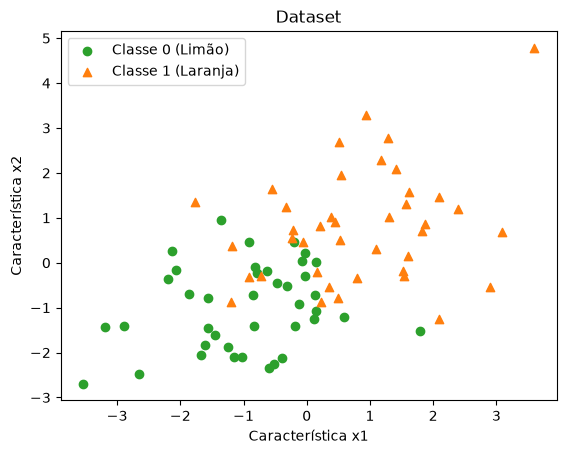

In [53]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Criar o dataset sintético
rng = np.random.default_rng(42)
m = 40
X0 = rng.normal(loc=[-1, -1], scale=1.3, size=(m, 2))
X1 = rng.normal(loc=[1, 1], scale=1.3, size=(m, 2))
X = np.vstack([X0, X1])
y = np.concatenate([np.zeros(m, dtype=int), np.ones(m, dtype=int)])

# Visualizar as frutas
plt.scatter(X[y == 0, 0], X[y == 0, 1], label="Classe 0 (Limão)", color='C2')
plt.scatter(X[y == 1, 0], X[y == 1, 1], label="Classe 1 (Laranja)", color='C1', marker='^')
plt.xlabel("Característica x1")
plt.ylabel("Característica x2")
plt.legend()
plt.title("Dataset")
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)


In [54]:
def distancias_loops(X_test, X_train):
    n_test, n_train = len(X_test), len(X_train)
    D = np.zeros((n_test, n_train))
    for i in range(n_test):
        for j in range(n_train):
            D[i, j] = np.sqrt(np.sum((X_test[i] - X_train[j]) ** 2))
    return D

def distancias_broadcasting(X_test, X_train):
    dif = X_test[:, None, :] - X_train[None, :, :]
    return np.sqrt(np.sum(dif ** 2, axis=2))

D = distancias_broadcasting(X_test, X_train)
k_val = 3
indices_vizinhos = np.argsort(D, axis=1, kind='stable')[:, :k_val]
rotulos_vizinhos = y_train[indices_vizinhos]

pred_loops = predict_loop(X_train, y_train, X_test, k=k_val)

knn_model = KNNDoZero(k=k_val).fit(X_train, y_train)
pred_broad = knn_model.predict(X_test)

D_a = distancias_loops(X_test, X_train)
D_b = distancias_broadcasting(X_test, X_train)
print("Mesmas distâncias?", np.allclose(D_a, D_b))
print("Mesmas previsões?", np.array_equal(pred_loops, pred_broad))


Mesmas distâncias? True
Mesmas previsões? True


In [55]:
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

knn_esc = KNNDoZero(k=3).fit(X_train_esc, y_train)
acc_teste = knn_esc.score(X_test_esc, y_test)

knn_sk = KNeighborsClassifier(n_neighbors=3).fit(X_train_esc, y_train)
acc_sk = knn_sk.score(X_test_esc, y_test)

print(f"Acurácia no Teste do KNNDoZero:{acc_teste:.2f}")
print(f"Acurácia no Teste do Sklearn: {acc_sk:.2f}")
print("Bateu?", np.isclose(acc_teste, acc_sk))


Acurácia no Teste do KNNDoZero:0.85
Acurácia no Teste do Sklearn: 0.85
Bateu? True
